dopo facciamo il python file, serve solo per veder le cose :D


In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import matthews_corrcoef,f1_score, confusion_matrix, precision_score, recall_score, balanced_accuracy_score
import matplotlib.pyplot as plt
import argparse
from collections import Counter
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def labeling_function(df):
    TN=df.loc[(df['true_class']==0) & (df['pred_class']==0)]['UniprotID'].tolist()

    TP=df.loc[(df['true_class']==1) & (df['pred_class']==1)]['UniprotID'].tolist()

    FN=df.loc[(df['true_class']==1) & (df['pred_class']==0)]['UniprotID'].tolist()

    FP=df.loc[(df['true_class']==0) & (df['pred_class']==1)]['UniprotID'].tolist()

    return TN, TP, FN, FP

In [3]:
def plot_taxa_distribution(FP,FN,data):
    FP_taxa=data.loc[data['ID'].isin(FP)]['kingdom'].value_counts()
    FN_taxa=data.loc[data['ID'].isin(FN)]['kingdom'].value_counts()

    taxa_df = pd.DataFrame({'False Positives': FP_taxa, 'False Negatives': FN_taxa})
    taxa_df_normalized = taxa_df.div(taxa_df.sum(axis=1), axis=0) * 100 

    taxa_df_normalized.plot(kind='bar', color=['red', 'blue'], alpha=0.5)


    plt.title('Distribution of False Positives and False Negatives across Taxa', weight='bold')
    plt.xlabel('Taxa')
    plt.ylabel('percentage')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('taxa_distribution.png', dpi=300)
    plt.show()

In [4]:

def Helix_presence(FP,data):
    FP_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == True)]['early_trans'].value_counts()
    FP_No_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == False)]['early_trans'].value_counts()

    counts = pd.DataFrame({'Helix Presence': FP_helix, 'No Helix Presence': FP_No_helix})

    counts.plot(kind='bar', color=['red', 'orange'], alpha=0.5)

    plt.title('Distribution of False Positives across Helix Presence', weight='bold')
    plt.xlabel('Helix Presence')
    plt.ylabel('Count')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('helix_distribution.png', dpi=300)
    plt.show()


In [5]:
df=pd.read_csv('/home/um40/LB2_project_Group_1/Models/SVM/SVM_pred_vs_test.csv')
data=pd.read_csv('/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv', sep='\t')
df_features =pd.read_csv('/home/um40/LB2_project_Group_1/SVM_method/feature.csv')

In [8]:
TN, TP, FN, FP= labeling_function(df)


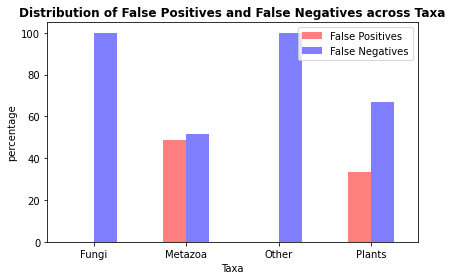

In [9]:
plot_taxa_distribution(FP,FN,data)

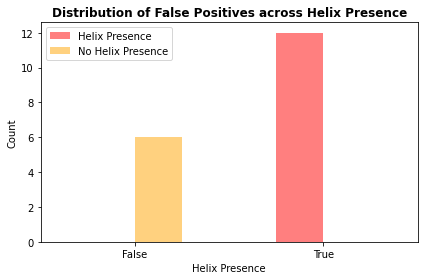

In [10]:
Helix_presence(FP,data)

## N term composition

1. composizione dei FN, estraiamo gli id dei fn, prendiao le sequenze fino a K(40) poi andiamo ad analizzarne la compositione. La paragoniamo ai veri positivi. Li paragoniamo ai positivi di training, ovvero tutti i fold tranne -1.

In [11]:
### extracts positive of benchmark
tp_id_train=data.loc[(data["fold"]!=-1)&(data["class"]==1)]['ID'].tolist()
tp_id_train

['O43155',
 'O43866',
 'O75629',
 'O94985',
 'P01579',
 'P02649',
 'P02774',
 'P04062',
 'P04275',
 'P04844',
 'P06028',
 'P07359',
 'P13671',
 'P16150',
 'P18510',
 'P19438',
 'P28039',
 'P28335',
 'P49767',
 'P50895',
 'P52798',
 'P55000',
 'P98066',
 'Q01151',
 'Q02083',
 'Q02747',
 'Q03405',
 'Q14802',
 'Q16568',
 'Q16627',
 'Q5ZPR3',
 'Q6UW88',
 'Q6UX27',
 'Q6UXD5',
 'Q6WN34',
 'Q86WA6',
 'Q86YD3',
 'Q86YL7',
 'Q8N126',
 'Q92563',
 'Q969N2',
 'Q96FE7',
 'Q9BQ51',
 'Q9GZX6',
 'Q9H293',
 'Q9UK23',
 'Q9Y2I2',
 'Q9Y6C2',
 'O14625',
 'O14773',
 'O15455',
 'O60602',
 'P01903',
 'P02462',
 'P05067',
 'P05164',
 'P08833',
 'P12318',
 'P13385',
 'P14384',
 'P14770',
 'P15289',
 'P20774',
 'P26842',
 'P31358',
 'P33681',
 'P36980',
 'P41271',
 'P43307',
 'P51654',
 'P55058',
 'P59665',
 'Q02809',
 'Q13007',
 'Q13421',
 'Q13433',
 'Q15399',
 'Q6UWI2',
 'Q6UWL6',
 'Q6UWN5',
 'Q6X4U4',
 'Q6ZSA7',
 'Q86Y34',
 'Q8NBK3',
 'Q8WWA0',
 'Q969J5',
 'Q96DR8',
 'Q96DU3',
 'Q99944',
 'Q9GZZ8',
 'Q9H1M4',

In [10]:
N_TERM = 40
fn_s_to_k=[] # False negative sequences (till pos 40=k) beloging to bechmark/test set 
tp_s_to_k=[] # True positive sequences (till pos 40=k) beloging to bechmark/test set 
tp_s_train_to_k=[] #True positive sequences (till pos 40=k) beloging to training set

with open('/home/um40/LB2_project_Group_1/von_Heijne_method/merged.fasta', 'r') as fasta_file:
    for line in fasta_file:
        if line.startswith('>'):
            if line.strip()[1:] in FN:
                seq=fasta_file.readline().strip()
                fn_s_to_k.append(seq[0:40])
            elif line.strip()[1:] in TP:
                seq=fasta_file.readline().strip()
                tp_s_to_k.append(seq[0:40])
            elif line.strip()[1:] in tp_id_train:
                seq=fasta_file.readline().strip()
                tp_s_train_to_k.append(seq[0:40])
            


In [11]:
AA_keys="ACDEFGHIKLMNPQRSTVWY"
def count_aa(seq, dict_aa):
    for aa in seq:
        if aa in AA_keys: #skip unknown residues
            dict_aa[aa]+=1
    return dict_aa


In [12]:
# Compute aa composition of FN of BENCHMARKING SET

dict_fn_b= Counter({aa: 0 for aa in AA_keys}) # initialization of the dictionary

for seq in fn_s_to_k:
    dict_fn_b=count_aa(seq,dict_fn_b) #update the dictionary for each FN seq beloging to benchmark set

# Normalize
for aa in dict_fn_b.keys():
    dict_fn_b[aa]=dict_fn_b[aa]/(40*len(fn_s_to_k))

dict_fn_b

Counter({'A': 0.09021739130434783,
         'C': 0.025,
         'D': 0.03152173913043478,
         'E': 0.030434782608695653,
         'F': 0.05,
         'G': 0.06847826086956521,
         'H': 0.020652173913043477,
         'I': 0.043478260869565216,
         'K': 0.041304347826086954,
         'L': 0.13695652173913042,
         'M': 0.04456521739130435,
         'N': 0.02826086956521739,
         'P': 0.08043478260869565,
         'Q': 0.02391304347826087,
         'R': 0.05434782608695652,
         'S': 0.08369565217391305,
         'T': 0.04565217391304348,
         'V': 0.06086956521739131,
         'W': 0.02282608695652174,
         'Y': 0.017391304347826087})

In [13]:
# Compute aa composition of TP of BENCHMARKING SET

dict_tp_b= Counter({aa: 0 for aa in AA_keys})

for seq in tp_s_to_k:
    dict_tp_b=count_aa(seq,dict_tp_b)

for aa in dict_tp_b.keys():
    dict_tp_b[aa]=dict_tp_b[aa]/(40*len(tp_s_to_k))

In [14]:
# Compute aa composition of TP of TRAINING SET
dict_tp_t= Counter({aa: 0 for aa in AA_keys})

for seq in tp_s_train_to_k:
    dict_tp_t=count_aa(seq,dict_tp_t)

for aa in dict_tp_t.keys():
    dict_tp_t[aa]=dict_tp_t[aa]/(40*len(tp_s_train_to_k))

grafico


In [15]:
groups = [
    "nonpolar",   # A
    "polar",      # C
    "negative",   # D
    "negative",   # E
    "aromatic",   # F
    "nonpolar",   # G
    "positive",   # H
    "nonpolar",   # I
    "positive",   # K
    "nonpolar",   # L
    "nonpolar",   # M
    "polar",      # N
    "nonpolar",   # P
    "polar",      # Q
    "positive",   # R
    "polar",      # S
    "polar",      # T
    "nonpolar",   # V
    "aromatic",   # W
    "aromatic",   # Y
]


In [16]:
df_fn_b=pd.DataFrame({'aa': dict_fn_b.keys(), 'count_fn_b': dict_fn_b.values()})
df_tp_b=pd.DataFrame({'aa': dict_tp_b.keys(), 'count_tp_b': dict_tp_b.values()})
df_tp_t=pd.DataFrame({'aa': dict_tp_t.keys(), 'count_tp_t': dict_tp_t.values()})

In [17]:
df_tp_b.head()

,aa,count_tp_b
0,A,0.118056
1,C,0.030808
2,D,0.030429
3,E,0.036490
4,F,0.043561


###

In [18]:
df_b_aa_dist= pd.merge(df_fn_b[['aa', 'count_fn_b']], df_tp_b[['aa', 'count_tp_b']], on='aa')
df=pd.merge(df_tp_t[['aa','count_tp_t']],df_b_aa_dist, on='aa')


In [19]:
df.head()

,aa,count_tp_t,count_fn_b,count_tp_b
0,A,0.109485,0.090217,0.118056
1,C,0.035108,0.025000,0.030808
2,D,0.030606,0.031522,0.030429
3,E,0.035476,0.030435,0.036490
4,F,0.042724,0.050000,0.043561


In [20]:
df['group']=groups

df.sort_values(by='group',inplace=True)

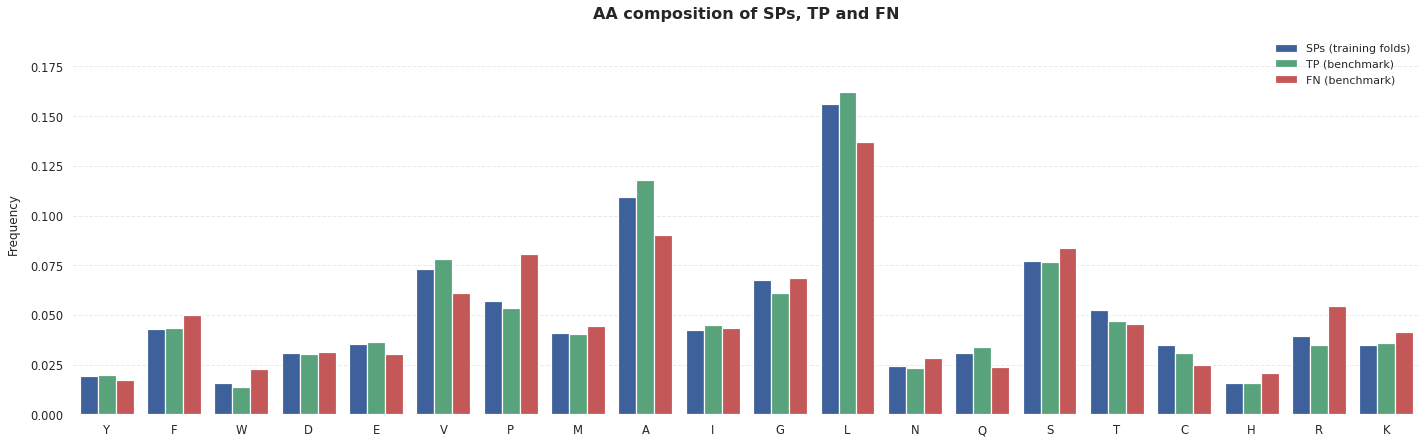

In [21]:
sns.set_theme(style="white", font_scale=1.05)
plt.rcParams['font.family'] = 'DejaVu Sans'

# ordine per gruppo, stabile
df = df.sort_values('group', kind='stable').reset_index(drop=True)
aa_order = df['aa'].tolist()
aa_to_group = dict(zip(df['aa'], df['group']))

label_map = {
    'count_tp_t': 'SPs (training folds)',
    'count_tp_b': 'TP (benchmark)',
    'count_fn_b': 'FN (benchmark)',
}
palette = {
    'SPs (training folds)': "#2E5EAA",
    'TP (benchmark)':       "#4CAF7A",
    'FN (benchmark)':       "#D64545",
}

df_melted = df.melt(id_vars='aa', value_vars=list(label_map),
                    var_name='dataset', value_name='Frequency')
df_melted['dataset'] = df_melted['dataset'].map(label_map)

fig, ax = plt.subplots(figsize=(20, 7.5))

sns.barplot(data=df_melted, x='aa', y='Frequency', hue='dataset',
            order=aa_order, hue_order=list(palette), palette=palette,
            edgecolor='white', linewidth=1.2, ax=ax)

# etichette (in %) sopra le barre

ax.set_ylim(0, df_melted['Frequency'].max() * 1.18)

ax.set_title('AA composition of SPs, TP and FN', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('')
ax.set_ylabel('Frequency', fontsize=12, labelpad=10)

sns.despine(left=True, bottom=True)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.legend(title='', frameon=False, loc='upper right', fontsize=11)



plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
plt.show()

   aa  count_tp_t  count_fn_b  count_tp_b     group
19  Y    0.019168    0.017391    0.019823  aromatic
4   F    0.042724    0.050000    0.043561  aromatic
18  W    0.015883    0.022826    0.013510  aromatic
2   D    0.030606    0.031522    0.030429  negative
3   E    0.035476    0.030435    0.036490  negative
Valori dopo il map: ['FN_test' 'TP_test' 'TP_train']
  aa     group   metric  Frequency
0  Y  aromatic  FN_test   0.017391
1  F  aromatic  FN_test   0.050000
2  W  aromatic  FN_test   0.022826
3  D  negative  FN_test   0.031522
4  E  negative  FN_test   0.030435


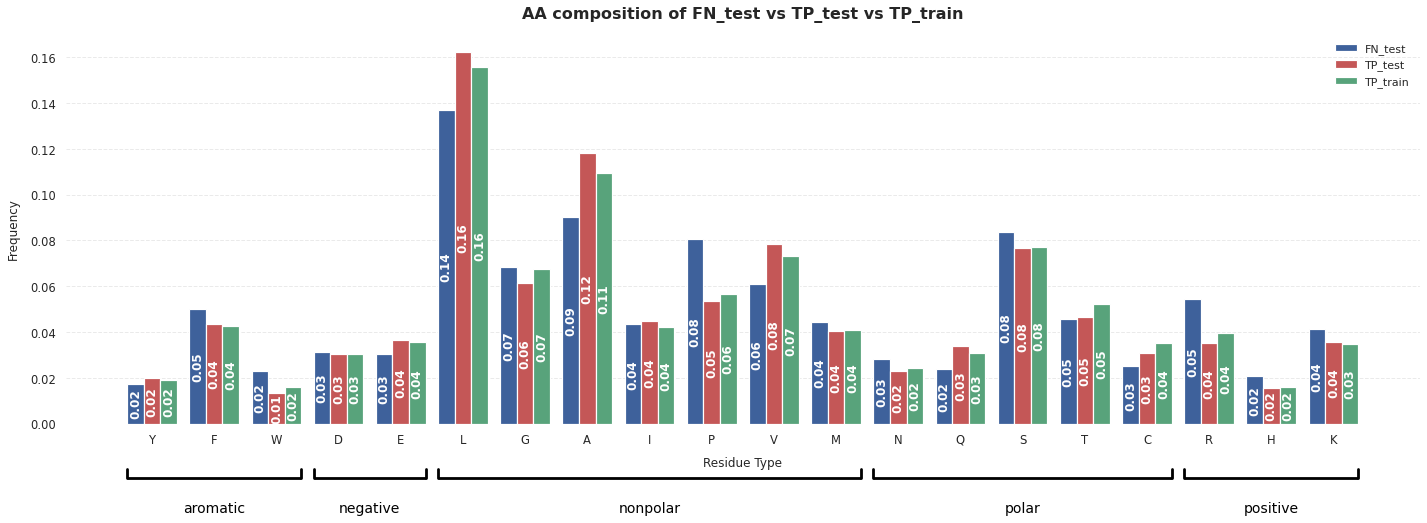

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Unione dei dataframe
df_b_aa_dist = pd.merge(df_fn_b[['aa', 'count_fn_b']], df_tp_b[['aa', 'count_tp_b']], on='aa')
df = pd.merge(df_tp_t[['aa', 'count_tp_t']], df_b_aa_dist, on='aa')
df['group'] = groups

# 2. Ordinamento iniziale
df.sort_values(by='group', inplace=True)

sns.set_theme(style="white", font_scale=1.05)
plt.rcParams['font.family'] = 'DejaVu Sans'

palette = {
    'FN_test': "#2E5EAA", 
    'TP_test': "#D64545", 
    'TP_train': "#4CAF7A"
}

print(df.head())

# 3. CORRETTO: Creazione di df_melted tramite pd.melt() 
# per trasformare le 3 colonne di conteggio in righe e mappare correttamente le etichette
# le colonne value_vars diventano un unica colonna che prende valori in {'count_fn_b', 'count_tp_b', 'count_tp_t'} mentre una nuova colonna value in cui viene inserito il valore che prima aveva la colonna corrispondente
df_melted = df.melt(
    id_vars=['aa', 'group'], 
    value_vars=['count_fn_b', 'count_tp_b', 'count_tp_t'],
    var_name='metric', 
    value_name='Frequency'
)

df_melted['metric'] = df_melted['metric'].map({
    'count_fn_b': 'FN_test', 
    'count_tp_b': 'TP_test', 
    'count_tp_t': 'TP_train'
})

print("Valori dopo il map:", df_melted['metric'].unique())
print(df_melted.head())

# Ordine degli amminoacidi raggruppati
aa_order = df.sort_values('group')['aa'].tolist()
aa_to_group = dict(zip(df['aa'], df['group']))

fig, ax = plt.subplots(figsize=(20, 7.5))

# 4. Passaggio di hue='metric' anziché 'aa'
sns.barplot(
    data=df_melted, 
    x='aa', 
    y='Frequency', 
    hue='metric',
    palette=palette, 
    edgecolor='white', 
    linewidth=1.2, 
    ax=ax,
    order=aa_order
)

# Etichette dentro/sopra le barre (corretti i segni meno mancanti)
for patch in ax.patches:
    height = patch.get_height()
    if pd.isna(height) or height == 0:
        continue
    ax.text(
        patch.get_x() + patch.get_width() / 2,
        height/2, 
        f'{height:.2f}',
        ha='center', va='center',
        rotation=90,
        fontsize=12, color='white', fontweight='bold'
    )

# Pulizia estetica
ax.set_title('AA composition of FN_test vs TP_test vs TP_train', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Residue Type', fontsize=12, labelpad=10)
ax.set_ylabel('Frequency', fontsize=12, labelpad=10)

sns.despine(left=True, bottom=True)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

ax.legend(title='', frameon=False, loc='upper right', fontsize=11)

# --- Graffe di gruppo sotto l'asse x (corretti i segni meno mancanti) ---
def add_group_brackets(ax, aa_order, aa_to_group, y_line=-0.14, y_text=-0.20,
                        tick_height=0.025, color='black', linewidth=2.8):
    trans = ax.get_xaxis_transform()
    groups_seq = [aa_to_group[a] for a in aa_order]
    segments = []
    start = 0
    for i in range(1, len(groups_seq) + 1):
        if i == len(groups_seq) or groups_seq[i] != groups_seq[start]:
            segments.append((start, i - 1, groups_seq[start]))  # <--- Corretto i - 1
            start = i

    for start_idx, end_idx, group in segments:
        x_start = start_idx - 0.4  # <--- Corretto start_idx - 0.4
        x_end = end_idx + 0.4

        ax.plot([x_start, x_end], [y_line, y_line],
                transform=trans, color=color, linewidth=linewidth,
                clip_on=False, solid_capstyle='butt')
        ax.plot([x_start, x_start], [y_line, y_line + tick_height],
                transform=trans, color=color, linewidth=linewidth, clip_on=False)
        ax.plot([x_end, x_end], [y_line, y_line + tick_height],
                transform=trans, color=color, linewidth=linewidth, clip_on=False)

        x_center = (x_start + x_end) / 2
        ax.text(x_center, y_text, group, transform=trans,
        ha='center', va='top', fontsize=14, color=color,
        clip_on=False)

add_group_brackets(ax, aa_order, aa_to_group, color='black')

plt.tight_layout()
plt.show()

# Signal peptide length distribution

- FNs may have a longer or shorter SP than expected
- Compare SP length distributions across the three groups (FN_benchmark, TP_benchmark, TP_train)

In [23]:
sp_length_FN = data.loc[data["ID"].isin(FN)]['cleavage_pos'].tolist()
sp_length_TP = data.loc[data["ID"].isin(TP)]['cleavage_pos'].tolist()
sp_length_TP_train = data.loc[data["ID"].isin(tp_id_train)]['cleavage_pos'].tolist()


**Spiegazione di kde:**

Immagina di avere l'età di un gruppo di persone. Per vedere qual è l'età più comune, di solito disegni un istogramma (le classiche barre verticali).
L'istogramma però ha un difetto: dipende da dove decidi di iniziare i "blocchi" (i bin). Spostando leggermente i confini dei blocchi, l'aspetto del grafico cambia parecchio e risulta "a gradini", poco naturale.

Il KDE risolve questo problema: invece di contare i dati dentro a dei blocchi rigidi, crea una curva liscia, continua e morbida che rappresenta la distribuzione dei dati.

In matematica e statistica, un kernel è semplicemente una funzione di peso simmetrica (spesso a forma di campana, simile a una gaussiana o a una normale).

"Stimare la densità" significa calcolare quanto i dati sono "affollati" in una certa zona.

Il processo del KDE funziona così:

1. Prendi ogni singolo dato e ci piazzi sopra una "collinetta" (il kernel).
2. Sommi tutte le collinette insieme.
3. Il risultato finale è un'unica curva continua.
4. Dove ci sono tanti dati vicini, le collinette si sommano e creano un picco alto (alta densità: lì ci sono molti valori).
5. Dove i dati sono pochi o isolati, la curva rimane bassa o piatta (bassa densità).

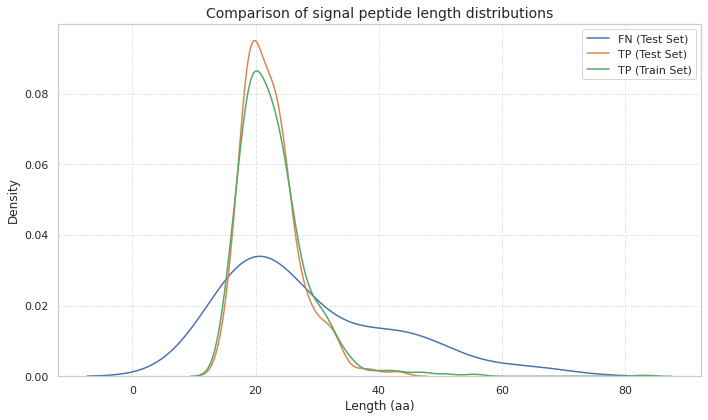

In [24]:
sns.set_theme(
 context='notebook',
 style='whitegrid',
 palette='deep',
 font='sans-serif',
 font_scale=1,
 color_codes=True,
 rc=None
)

plt.figure(figsize=(10, 6))

# Plot delle distribuzioni con KDE (Kernel Density Estimation)
# kde computes the esimate kernel density, and this is necessary for correctly comparing the three lists in the same graph
# because they have different length (= diff #seq) 
sns.kdeplot(sp_length_FN, label='FN (Test Set)', palette="rocket")
sns.kdeplot(sp_length_TP, label='TP (Test Set)', palette="rocket")
sns.kdeplot(sp_length_TP_train, label='TP (Train Set)', palette="rocket")

# Style
plt.title('Comparison of signal peptide length distributions', fontsize=14)
plt.xlabel('Length (aa)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

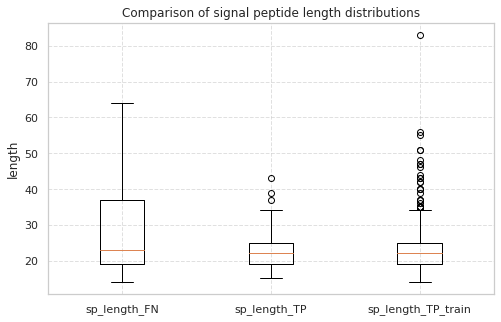

In [25]:
plt.figure(figsize=(8, 5))
plt.boxplot([sp_length_FN, sp_length_TP, sp_length_TP_train], labels=['sp_length_FN', 'sp_length_TP', 'sp_length_TP_train'])

plt.title('Comparison of signal peptide length distributions')
plt.ylabel('length')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Other features distribution

In [26]:
feature_names_dict = {
    "max_kd": "Maximum Kyte-Doolittle Hydrophobicity",
    "p_max_kd": "Position of Maximum Kyte-Doolittle Hydrophobicity",
    "kd_len": "Length of Hydrophobic Region",
    "kd_dakay": "Kyte-Doolittle Hydrophobicity decay",
    "max_charge_pos": "Maximum Positive Charge",
    "max_charge_pos_p": "Position of Maximum Positive Charge",
    "max_charge_neg": "Maximum Negative Charge",
    "max_charge_neg_p": "Position of Maximum Negative Charge",
    "nfh_max": "Maximum NFH Score",
    "nfh_p": "Position of Maximum NFH Score",
    "nfb_max": "Maximum NFB Score",
    "nfb_p": "Position of Maximum NFB Score",
    "res_vol_mean": "Mean Residue Volume",
    "signal_max": "Maximum Signal Peptide Score",
    "signal_max_p": "Position of Maximum Signal Peptide Score",
    "flexibility_mean": "Mean Protein Flexibility",
    "mut_mean": "Mean Mutation Score",
    "A": "Alanine Frequency",
    "C": "Cysteine Frequency",
    "D": "Aspartic Acid Frequency",
    "E": "Glutamic Acid Frequency",
    "F": "Phenylalanine Frequency",
    "G": "Glycine Frequency",
    "H": "Histidine Frequency",
    "I": "Isoleucine Frequency",
    "K": "Lysine Frequency",
    "L": "Leucine Frequency",
    "M": "Methionine Frequency",
    "N": "Asparagine Frequency",
    "P": "Proline Frequency",
    "Q": "Glutamine Frequency",
    "R": "Arginine Frequency",
    "S": "Serine Frequency",
    "T": "Threonine Frequency",
    "V": "Valine Frequency",
    "W": "Tryptophan Frequency",
    "Y": "Tyrosine Frequency"
}

In [27]:
def feature_distributions_boxplot(FN_id_test, TP_id_test, TP_id_train, df_features, feature):
    FN_test = df_features.loc[df_features["id"].isin(FN_id_test)][feature].tolist() 
    TP_test = df_features.loc[df_features["id"].isin(TP_id_test)][feature].tolist()
    TP_train = df_features.loc[df_features["id"].isin(TP_id_train)][feature].tolist()

    plt.figure(figsize=(8, 5))
    plt.boxplot([FN_test, TP_test, TP_train], labels=['FN test', 'TP test', 'TP train'])

    plt.title(f'Comparison of {feature_names_dict[feature]} distributions')
    plt.ylabel(feature_names_dict[feature])
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()


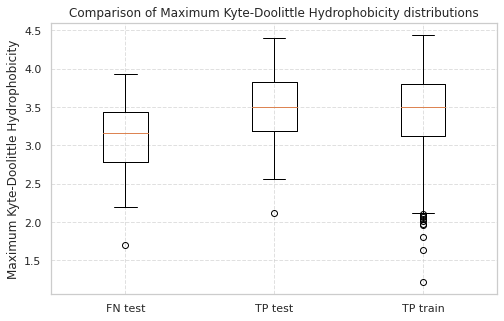

In [28]:
feature_distributions_boxplot(FN, TP, tp_id_train, df_features, 'max_kd')

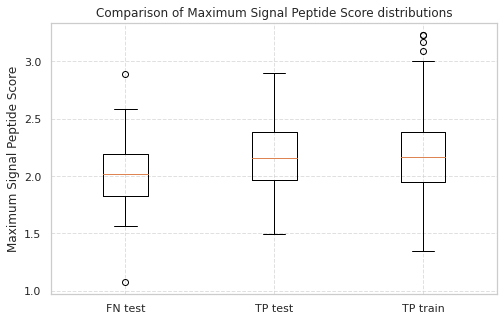

In [29]:
feature_distributions_boxplot(FN, TP, tp_id_train, df_features, 'signal_max')

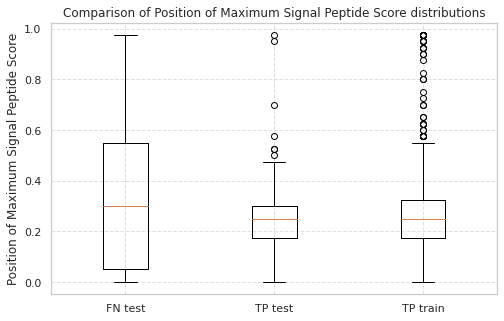

In [30]:
feature_distributions_boxplot(FN, TP, tp_id_train, df_features, 'signal_max_p')